# GSM8K entropy ROC AUC across models

Compare **first**, **last**, **mean**, **maximum**, and **minimum** token entropy for each model's direct responses on the GSM8K training set.

**Positive class: incorrect answer.** Higher entropy predicts an incorrect answer, so AUC > 0.5 indicates useful discrimination. This is equivalent to treating correctness as positive and negating entropy. Scores are never flipped automatically when AUC < 0.5.

Offline GSM8K scripts use `MultiTokenEntropyEstimator`: they generate up to 10 tokens and exclude a final token whose ID matches `tokenizer.eos_token_id`. Statistics cover the entire remaining generated response, which may include formatting or unwanted explanation, rather than an explicitly extracted numeric-answer span. Training-time resampling instead uses first-token entropy.

Use the normalized Parquets by default. Dividing entropy by a positive per-model constant does not change within-model ROC AUC. Each model is evaluated against its **own stored correctness labels**, with the same finite-score rows used for every entropy type within that model.


In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve

for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (directory / "src/core").is_dir() and (directory / "data/out").is_dir():
        REPO_ROOT = directory
        break
else:
    raise FileNotFoundError("Run this notebook from inside the recursive_caft repository.")

# Change to "single_token_entropy" to analyze the original offline files.
DATA_DIR = REPO_ROOT / "data/out/single_token_entropy_normalized"
OUT_DIR = REPO_ROOT / "artifacts/analysis/gsm8k_entropy_roc_auc"
CORRECTNESS_COLUMN = "model_answer_correct"
METRICS = {
    "first_token_entropy": "First token",
    "last_token_entropy": "Last token",
    "mean_entropy": "Mean",
    "max_entropy": "Maximum",
    "min_entropy": "Minimum",
}
MODEL_LABELS = {
    "llama_3b": "Llama 3B",
    "llama_70b": "Llama 70B",
    "mistral_24b": "Mistral 24B",
    "phi4mini": "Phi-4 Mini",
    "qwen_3b": "Qwen 3B",
    "qwen_32b": "Qwen 32B",
    "qwen_72b": "Qwen 72B",
}
sns.set_theme(style="whitegrid", context="notebook")
print(f"Data: {DATA_DIR.relative_to(REPO_ROOT)}")


Data: data/out/single_token_entropy_normalized


## Data coverage and answer diagnostics

Report exclusions, class counts, response lengths, and the fraction of outputs that look like a single number. Stored correctness is used without recomputation. Zero entropy is valid and is retained.

Low accuracy or many nonnumeric responses can make the result reflect answer formatting or instruction following as well as arithmetic uncertainty. The 10-token limit can truncate responses; the scored-token count alone does not identify truncation conclusively.


In [2]:
files = sorted(DATA_DIR.glob("gsm8k_*.parquet"))
if not files:
    raise FileNotFoundError(f"No GSM8K Parquets found in {DATA_DIR}")

frames = {}
coverage_rows = []
for path in files:
    model = path.stem.removeprefix("gsm8k_")
    df = pd.read_parquet(path)
    required = {CORRECTNESS_COLUMN, "question_id", "model_answer", "scored_tokens", *METRICS}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path.name}: missing columns {sorted(missing)}")
    if df["question_id"].duplicated().any():
        raise ValueError(f"{path.name}: duplicate question IDs")
    labels = df[CORRECTNESS_COLUMN]
    if not labels.dropna().isin([True, False]).all():
        raise ValueError(f"{path.name}: correctness must be boolean or 0/1")

    scores = df[list(METRICS)].apply(pd.to_numeric, errors="coerce")
    valid = labels.notna() & np.isfinite(scores).all(axis=1)
    usable = df.loc[valid].copy()
    usable[list(METRICS)] = scores.loc[valid]
    usable["incorrect"] = ~labels.loc[valid].astype(bool)
    usable["num_scored_tokens"] = usable["scored_tokens"].map(len)
    frames[model] = usable
    numeric_response = usable["model_answer"].fillna("").astype(str).str.strip().str.fullmatch(
        r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)"
    )
    coverage_rows.append({
        "model": model,
        "label": MODEL_LABELS.get(model, model),
        "rows_loaded": len(df),
        "rows_used": len(usable),
        "rows_excluded": int((~valid).sum()),
        "correct": int((~usable["incorrect"]).sum()),
        "incorrect": int(usable["incorrect"].sum()),
        "accuracy": (~usable["incorrect"]).mean(),
        "single_number_fraction": numeric_response.mean(),
        "mean_scored_tokens": usable["num_scored_tokens"].mean(),
        "multi_token_rows": int(usable["num_scored_tokens"].ge(2).sum()),
    })

model_order = [model for model in MODEL_LABELS if model in frames]
model_order += sorted(set(frames) - set(model_order))
coverage = pd.DataFrame(coverage_rows).set_index("model").loc[model_order].reset_index()
display(coverage.round(4))


,model,label,rows_loaded,rows_used,rows_excluded,correct,incorrect,accuracy,single_number_fraction,mean_scored_tokens,multi_token_rows
0,llama_3b,Llama 3B,7473,7473,0,23,7450,0.0031,0.0642,9.1946,7022
1,llama_70b,Llama 70B,7473,7473,0,851,6622,0.1139,0.2652,7.5794,5645
2,mistral_24b,Mistral 24B,7473,7473,0,1124,6349,0.1504,0.9510,3.0284,7039
3,phi4mini,Phi-4 Mini,7473,7473,0,504,6969,0.0674,0.4322,5.4192,7473
4,qwen_3b,Qwen 3B,7473,7473,0,1281,6192,0.1714,0.9933,2.4100,6374
5,qwen_32b,Qwen 32B,7473,7473,0,4494,2979,0.6014,0.9999,2.3660,6248
6,qwen_72b,Qwen 72B,7473,7473,0,3839,3634,0.5137,0.9988,2.4468,6409


## AUC table and heatmap

AUC is undefined if the evaluated subset contains only one class; those entries are left missing and carry a status in the detailed table. No entropy threshold is selected. These are descriptive point estimates on the available training data.


In [3]:
def evaluate_auc(model, df, subset):
    rows = []
    for metric in METRICS:
        has_two_classes = df["incorrect"].nunique() == 2
        auc = roc_auc_score(df["incorrect"], df[metric]) if has_two_classes else np.nan
        rows.append({
            "model": model,
            "entropy_type": metric,
            "subset": subset,
            "roc_auc": auc,
            "rows_used": len(df),
            "correct": int((~df["incorrect"]).sum()),
            "incorrect": int(df["incorrect"].sum()),
            "status": "ok" if has_two_classes else "fewer than two classes",
        })
    return rows

auc_rows = []
for model in model_order:
    df = frames[model]
    auc_rows.extend(evaluate_auc(model, df, "all"))
    auc_rows.extend(evaluate_auc(model, df.loc[df["num_scored_tokens"].ge(2)], "multi_token"))
auc_results = pd.DataFrame(auc_rows)

auc_table = (
    auc_results.query("subset == 'all'")
    .pivot(index="model", columns="entropy_type", values="roc_auc")
    .reindex(index=model_order, columns=list(METRICS))
)
display(auc_table.rename(index=MODEL_LABELS, columns=METRICS).round(4))

best_rows = []
for model in model_order:
    values = auc_table.loc[model].dropna()
    best_rows.append({
        "model": MODEL_LABELS.get(model, model),
        "best_entropy_type": ", ".join(METRICS[m] for m in values.index[values.eq(values.max())])
            if not values.empty else "undefined",
        "best_auc": values.max() if not values.empty else np.nan,
        "first_token_auc": auc_table.loc[model, "first_token_entropy"],
        "mean_auc": auc_table.loc[model, "mean_entropy"],
    })
best_by_model = pd.DataFrame(best_rows)
display(best_by_model.round(4))


entropy_type,First token,Last token,Mean,Maximum,Minimum
model,,,,,
Llama 3B,0.5534,0.1122,0.1146,0.5698,0.0443
Llama 70B,0.7722,0.4660,0.6855,0.8603,0.1724
Mistral 24B,0.7264,0.7116,0.7574,0.7957,0.6819
Phi-4 Mini,0.7113,0.5869,0.5149,0.7398,0.3641
Qwen 3B,0.7114,0.6665,0.7411,0.7576,0.6480
Qwen 32B,0.7847,0.7549,0.8492,0.8506,0.7330
Qwen 72B,0.7968,0.7084,0.8393,0.8470,0.6885


,model,best_entropy_type,best_auc,first_token_auc,mean_auc
0,Llama 3B,Maximum,0.5698,0.5534,0.1146
1,Llama 70B,Maximum,0.8603,0.7722,0.6855
2,Mistral 24B,Maximum,0.7957,0.7264,0.7574
3,Phi-4 Mini,Maximum,0.7398,0.7113,0.5149
4,Qwen 3B,Maximum,0.7576,0.7114,0.7411
5,Qwen 32B,Maximum,0.8506,0.7847,0.8492
6,Qwen 72B,Maximum,0.8470,0.7968,0.8393


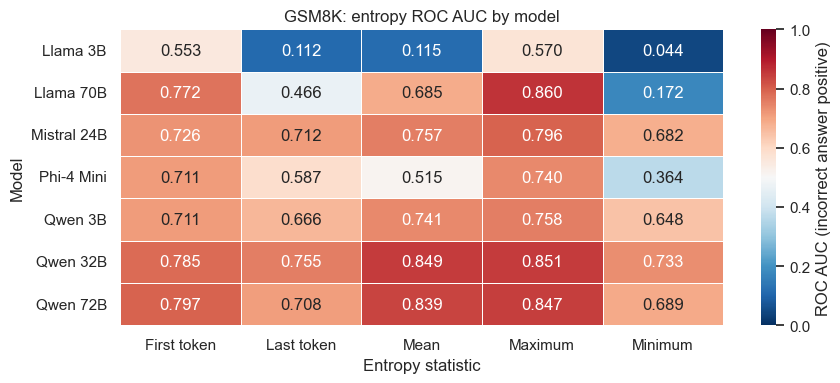

In [4]:
fig_heatmap, ax = plt.subplots(figsize=(9, max(4, len(model_order) * 0.55)))
sns.heatmap(
    auc_table.rename(index=MODEL_LABELS, columns=METRICS),
    annot=True, fmt=".3f", vmin=0, vmax=1, center=0.5,
    cmap="RdBu_r", linewidths=0.5, ax=ax,
    cbar_kws={"label": "ROC AUC (incorrect answer positive)"},
)
ax.set(title="GSM8K: entropy ROC AUC by model", xlabel="Entropy statistic", ylabel="Model")
fig_heatmap.tight_layout()
plt.show()


## ROC curves for each model

Curves use the same rows as the full-data AUC table. The diagonal is chance performance. An incorrect response is a positive; a correct response is a negative.


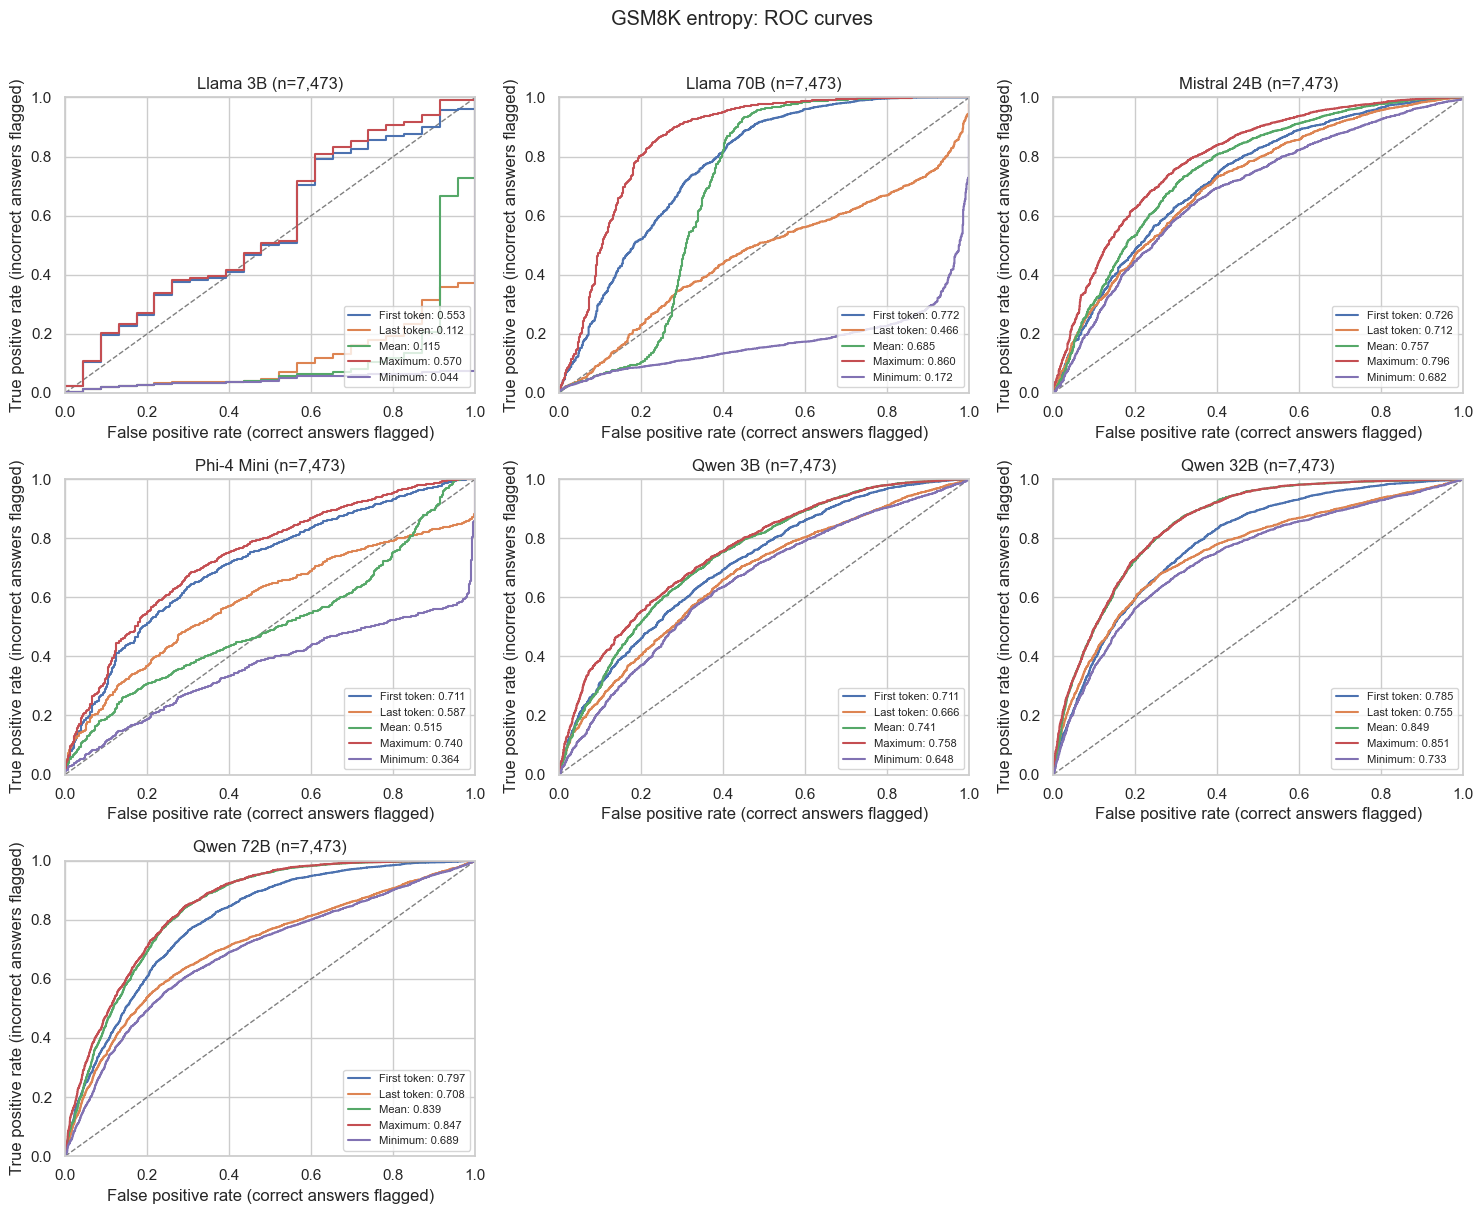

In [5]:
ncols = 3
nrows = math.ceil(len(model_order) / ncols)
fig_roc, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows), squeeze=False)
palette = dict(zip(METRICS, sns.color_palette("deep", len(METRICS))))
for ax, model in zip(axes.flat, model_order):
    df = frames[model]
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
    if df["incorrect"].nunique() == 2:
        for metric, label in METRICS.items():
            fpr, tpr, _ = roc_curve(df["incorrect"], df[metric])
            ax.plot(fpr, tpr, color=palette[metric],
                    label=f"{label}: {auc_table.loc[model, metric]:.3f}", linewidth=1.5)
        ax.legend(fontsize=8, loc="lower right")
    else:
        ax.text(0.5, 0.5, "AUC undefined: fewer than two classes", ha="center", wrap=True)
    ax.set(
        title=f"{MODEL_LABELS.get(model, model)} (n={len(df):,})",
        xlabel="False positive rate (correct answers flagged)",
        ylabel="True positive rate (incorrect answers flagged)",
        xlim=(0, 1), ylim=(0, 1),
    )
for ax in list(axes.flat)[len(model_order):]:
    ax.set_visible(False)
fig_roc.suptitle("GSM8K entropy: ROC curves", y=1.01)
fig_roc.tight_layout()
plt.show()


## Responses with multiple scored tokens

For one-token responses, all five statistics coincide. Restricting to at least two scored tokens makes their differences easier to assess. This is a different response-length subset for each model, so its AUC should not be interpreted as an isolated causal effect of length.

The delta columns compare each statistic with first-token entropy **on the same subset**.


In [6]:
multi_auc_table = (
    auc_results.query("subset == 'multi_token'")
    .pivot(index="model", columns="entropy_type", values="roc_auc")
    .reindex(index=model_order, columns=list(METRICS))
)
display(multi_auc_table.rename(index=MODEL_LABELS, columns=METRICS).round(4))
auc_deltas = pd.DataFrame({
    "mean_minus_first_all": auc_table["mean_entropy"] - auc_table["first_token_entropy"],
    "max_minus_first_all": auc_table["max_entropy"] - auc_table["first_token_entropy"],
    "mean_minus_first_multi": multi_auc_table["mean_entropy"] - multi_auc_table["first_token_entropy"],
    "max_minus_first_multi": multi_auc_table["max_entropy"] - multi_auc_table["first_token_entropy"],
}).join(coverage.set_index("model")[["multi_token_rows"]])
display(auc_deltas.rename(index=MODEL_LABELS).round(4))


entropy_type,First token,Last token,Mean,Maximum,Minimum
model,,,,,
Llama 3B,0.4902,0.2716,0.0151,0.4991,0.0134
Llama 70B,0.7627,0.7602,0.7466,0.8734,0.3236
Mistral 24B,0.7325,0.7486,0.7862,0.8023,0.7227
Phi-4 Mini,0.7113,0.5869,0.5149,0.7398,0.3641
Qwen 3B,0.7188,0.6947,0.7640,0.7657,0.6913
Qwen 32B,0.7810,0.7615,0.8543,0.8523,0.7511
Qwen 72B,0.8004,0.7267,0.8485,0.8480,0.7195


,mean_minus_first_all,max_minus_first_all,mean_minus_first_multi,max_minus_first_multi,multi_token_rows
model,,,,,
Llama 3B,-0.4388,0.0165,-0.4751,0.0088,7022
Llama 70B,-0.0867,0.0881,-0.0161,0.1107,5645
Mistral 24B,0.0310,0.0693,0.0537,0.0698,7039
Phi-4 Mini,-0.1964,0.0284,-0.1964,0.0284,7473
Qwen 3B,0.0296,0.0462,0.0453,0.0469,6374
Qwen 32B,0.0644,0.0658,0.0733,0.0714,6248
Qwen 72B,0.0425,0.0502,0.0481,0.0477,6409


## Export results

Write reusable tables and PNG/PDF figures under `artifacts/analysis/gsm8k_entropy_roc_auc`. Filenames identify whether the input Parquets were normalized.


In [7]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
source_tag = DATA_DIR.name
coverage.to_csv(OUT_DIR / f"{source_tag}_coverage.csv", index=False)
auc_results.to_csv(OUT_DIR / f"{source_tag}_auc_results.csv", index=False)
best_by_model.to_csv(OUT_DIR / f"{source_tag}_best_by_model.csv", index=False)
auc_deltas.to_csv(OUT_DIR / f"{source_tag}_auc_deltas.csv")
for name, fig in (("heatmap", fig_heatmap), ("roc_curves", fig_roc)):
    for extension in ("png", "pdf"):
        fig.savefig(OUT_DIR / f"{source_tag}_{name}.{extension}", dpi=160, bbox_inches="tight")
print(f"Saved results to {OUT_DIR.relative_to(REPO_ROOT)}")


Saved results to artifacts/analysis/gsm8k_entropy_roc_auc
